# Current opening-model results
Validation uses the train-only fit; test uses the train + validation fit. Opening, close1 and close2 inputs share the fitted opening model. Plot paths are explicit below, and coefficient tables are returned in `coefficient_tables` and saved as CSVs. Only regularized prediction-model coefficient tables are generated.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, brier_score_loss
from ufc_betting.config import config, settings
from ufc_betting.Models.LogisticRegression.visual_functions import (
    plot_model_metrics, analyze_line_movement_perf, plot_juice_histogram,
)
from ufc_betting.Models.LogisticRegression.utils import calc_net_odds, print_gender_accuracy


In [11]:
# Preserve the existing model-metrics and Vegas plot destinations.
predictions_dir = settings.model_predictions_folder
plots_dir = settings.images_dir / "plot_pngs"
vegas_plots_dir = settings.data_dir / "plot_pngs"
coefficients_dir = settings.data_dir / "model_results" / "coefficients"
for directory in (plots_dir, vegas_plots_dir, coefficients_dir):
    directory.mkdir(parents=True, exist_ok=True)
markets = ("open", "close1", "close2")
prediction_paths = {
    (split, f"open_with_{market}"): predictions_dir / f"{split}_logit_open_with_{market}.csv"
    for split in ("val", "test") for market in markets
}
model_plot_paths = {
    (split, f"open_with_{market}"): plots_dir / f"{split}_open_with_{market}_model_metrics.png"
    for split in ("val", "test") for market in markets
}
# The train-only workflow saves opening validation metrics under this name.
model_plot_paths[("val", "open_with_open")] = plots_dir / "val_open_model_metrics.png"
predictions = {}
for key, path in prediction_paths.items():
    frame = pd.read_csv(path)
    frame = frame.loc[frame["winner"].isin([0, 1])].copy()
    frame["date"] = pd.to_datetime(frame["date"])
    if frame.empty or frame["winner"].nunique() < 2:
        raise ValueError(f"{path}: metric plots require both outcome classes")
    for market in markets:
        for side in ("red", "blue"):
            # New prediction frames retain fair decimal odds, not fair probabilities.
            frame[f"proba_fair_{market}_{side}"] = 1 / frame[f"dec_fair_{market}_{side}"]
    predictions[key] = frame


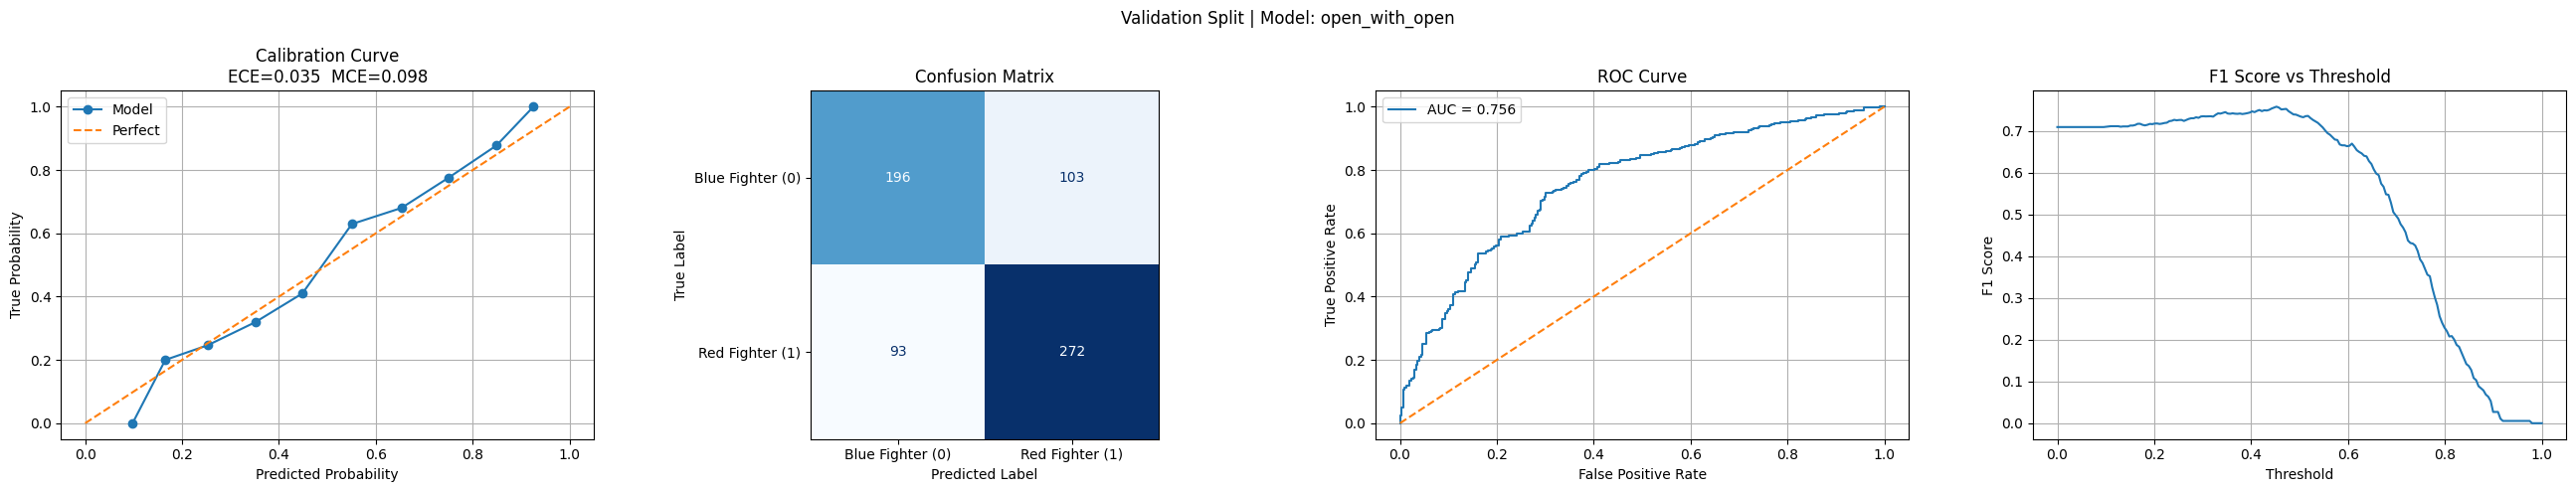

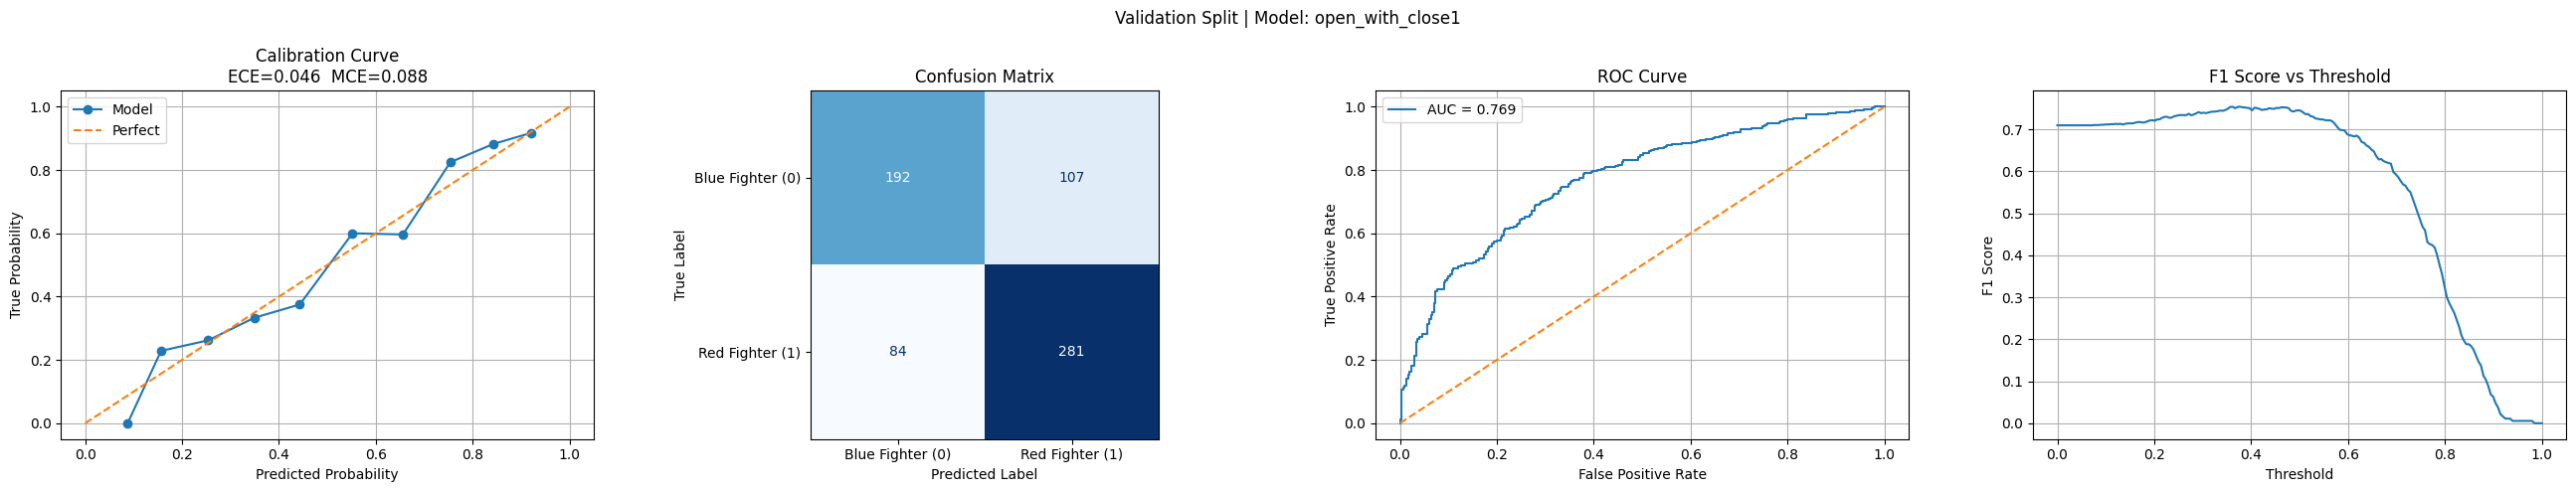

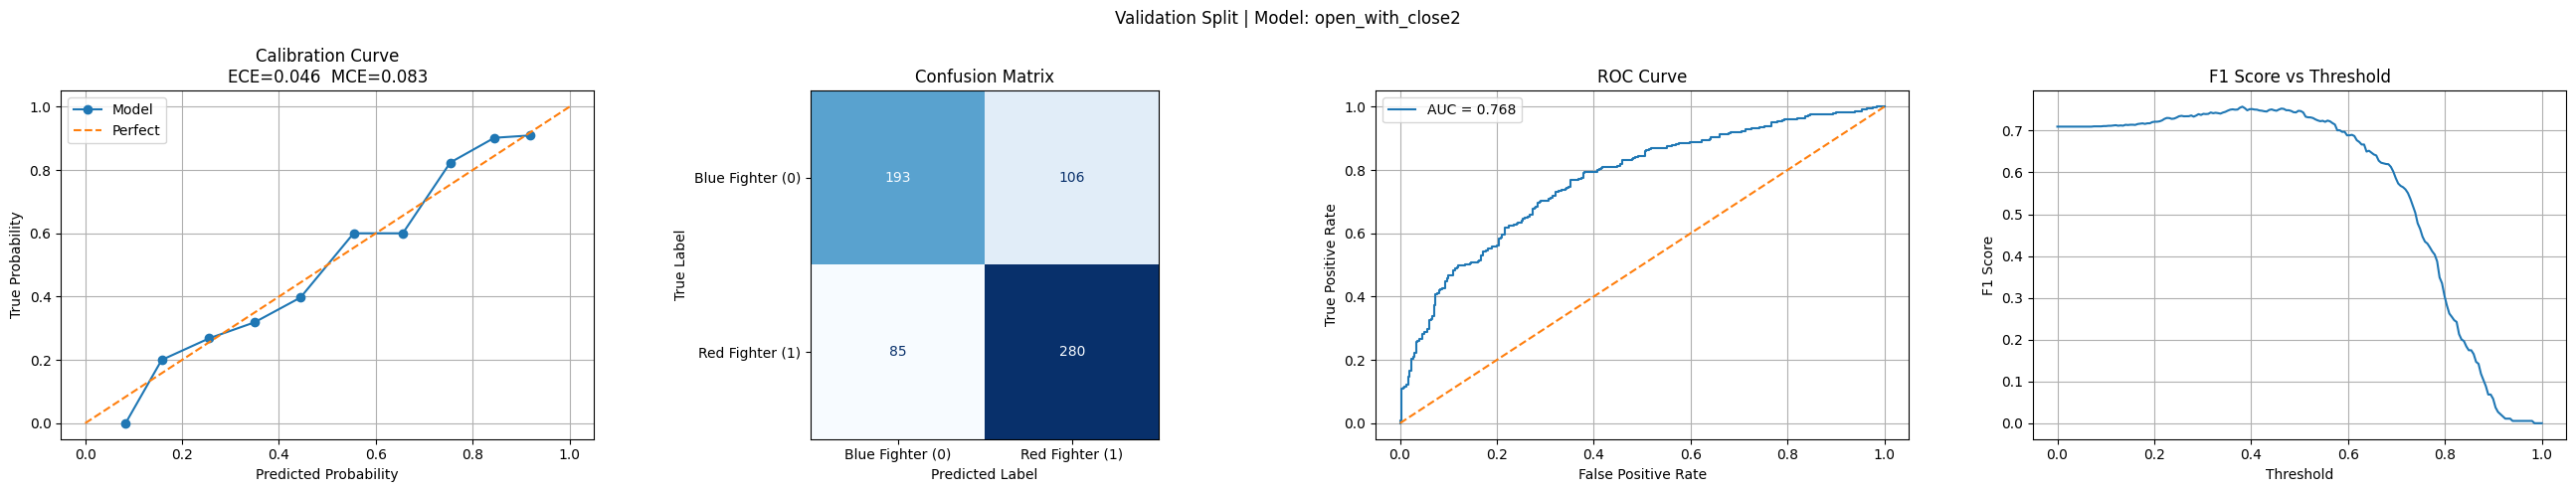

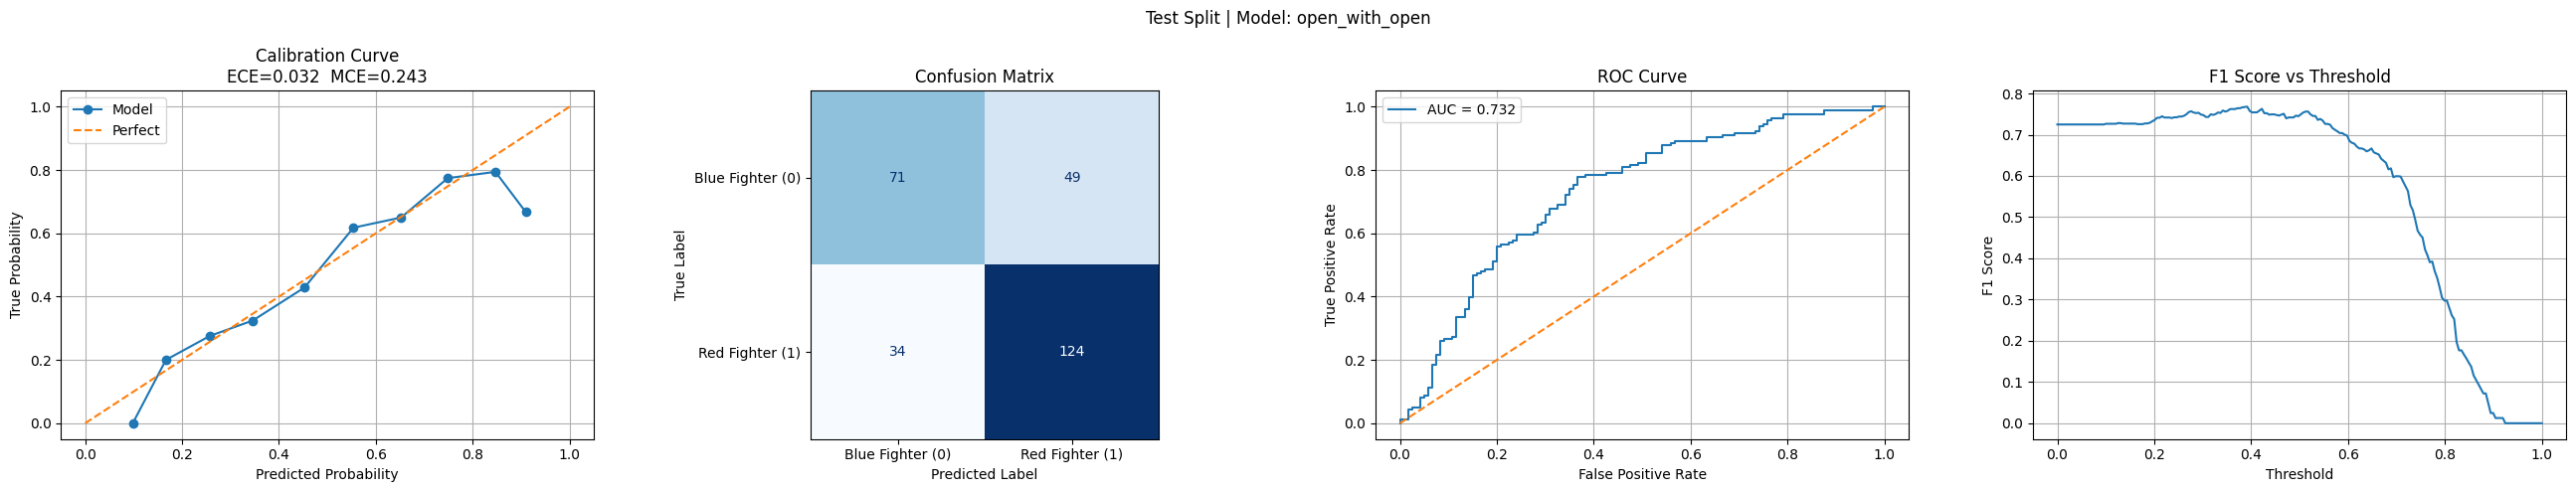

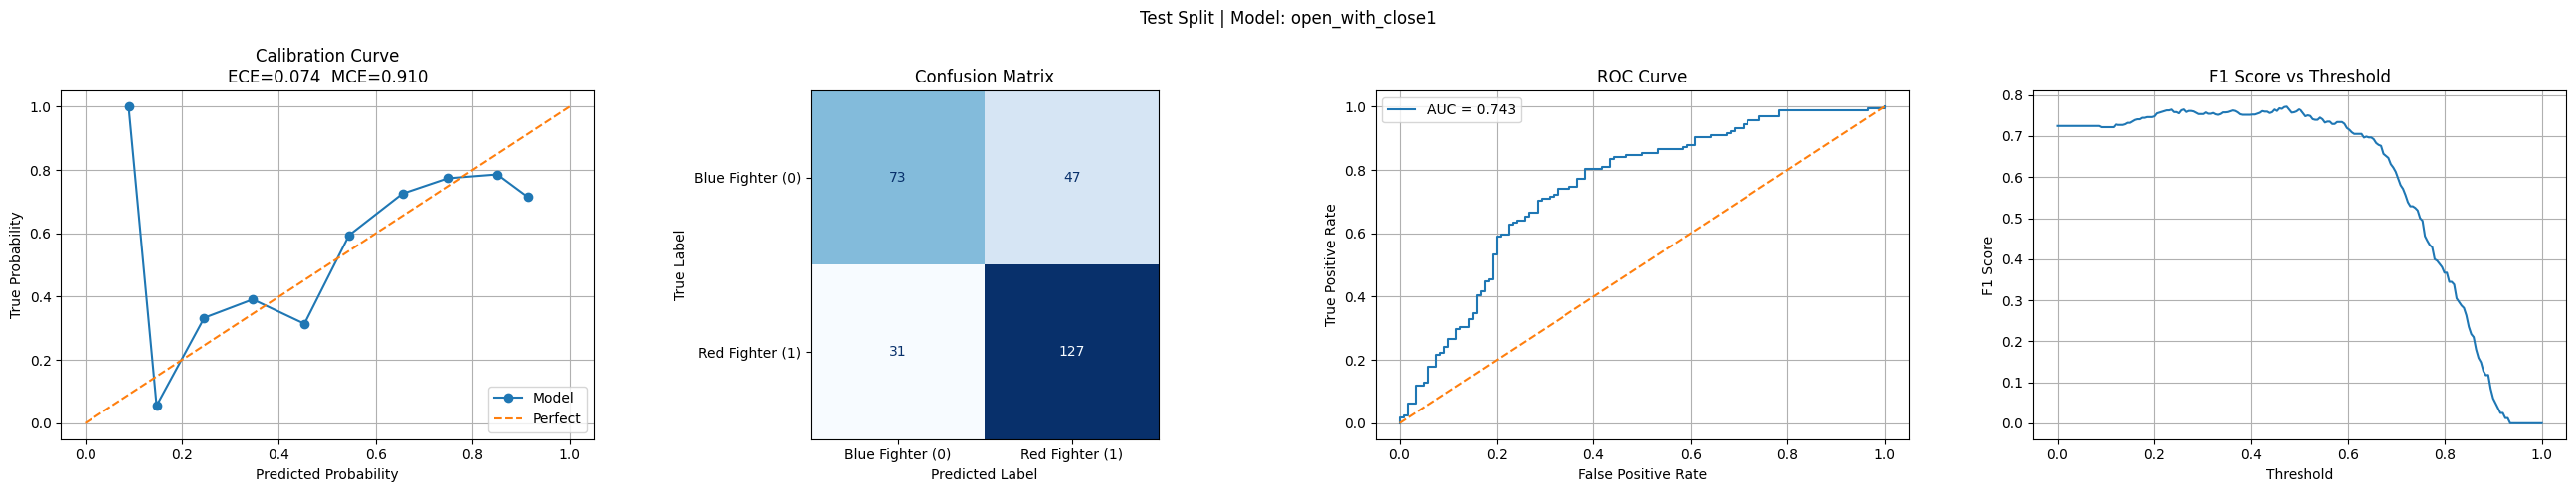

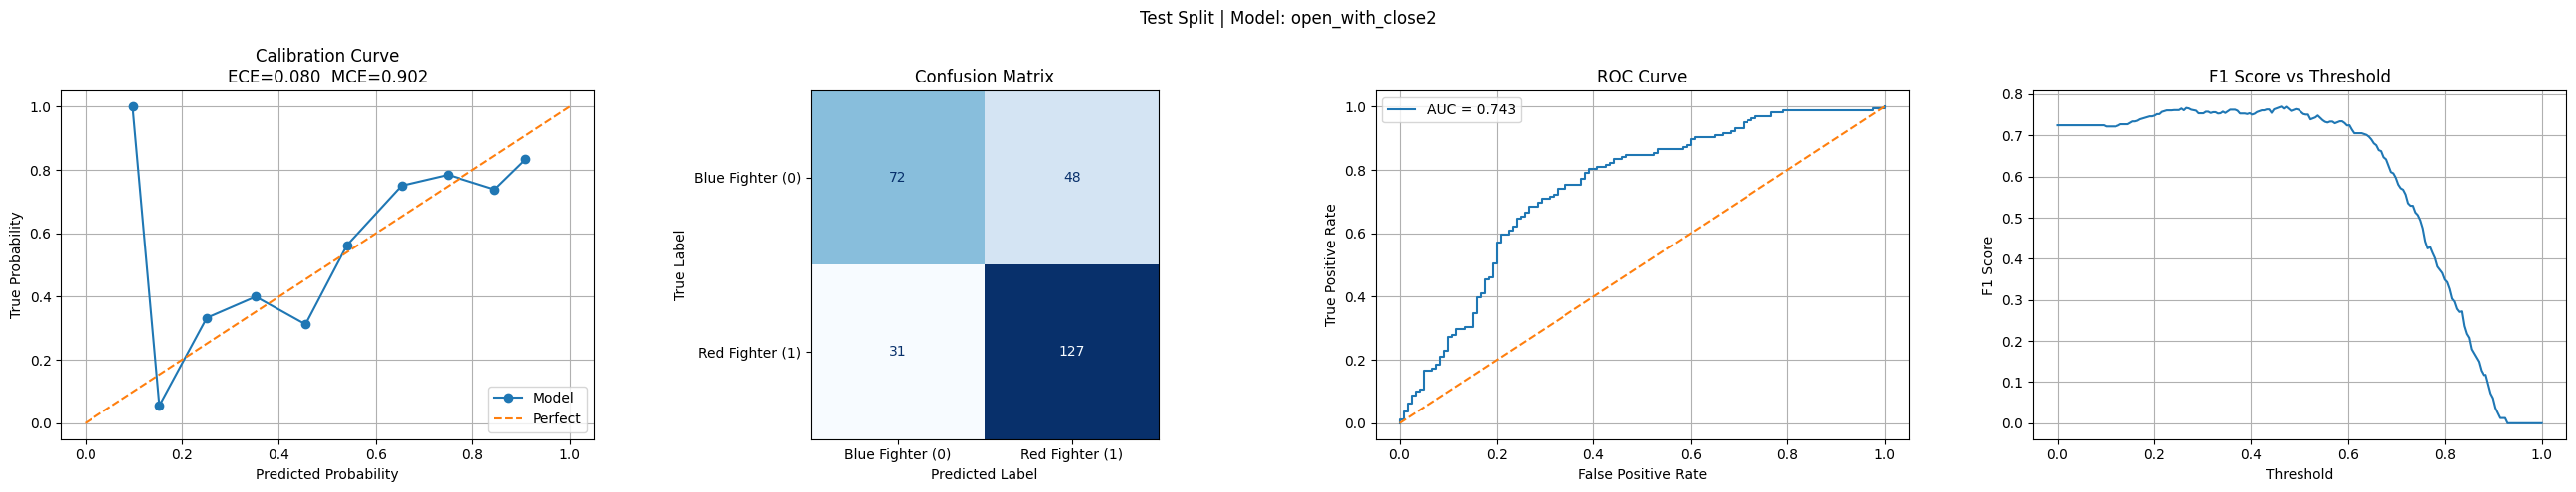

In [12]:
metric_figures = {}
for (split, model_type), frame in predictions.items():
    split_label = "Validation" if split == "val" else "Test"
    plot_model_metrics(
        frame["winner"].to_numpy(), frame["pred_winner"].to_numpy(),
        frame["proba_red"].to_numpy(),
        suptitle=f"{split_label} Split | Model: {model_type}",
        path=model_plot_paths[(split, model_type)],
    )
    metric_figures[(split, model_type)] = plt.gcf()
    plt.close(metric_figures[(split, model_type)])


In [13]:
# Closing inputs reuse the opening model coefficients; they are not separate fits.
# Export only the regularized prediction models.
# All three current variants use the regularized train + validation fit.
model_paths = {
    "open_with_open_trainval": config.model_open_test_path,
    "open_with_close1_trainval": config.model_open_test_path,
    "open_with_close2_trainval": config.model_open_test_path,
}
coefficient_paths = {name: coefficients_dir / f"{name}_coefficients.csv" for name in model_paths}

def coefficient_summary(model):
    names = model.model.exog_names
    intervals = np.asarray(model.conf_int())
    table = pd.DataFrame({
        "coefficient": np.asarray(model.params),
        "std_error": np.asarray(model.bse),
        "z": np.asarray(model.tvalues),
        "p_value": np.asarray(model.pvalues),
        "ci_lower": intervals[:, 0], "ci_upper": intervals[:, 1],
    }, index=pd.Index(names, name="variable"))
    p = table["p_value"]
    table["significance"] = np.select([p < .001, p < .01, p < .05], ["***", "**", "*"], default="")
    return table.round(4)

coefficient_tables = {}
trainval_model = sm.load(config.model_open_test_path)
for name in model_paths:
    table = coefficient_summary(trainval_model)
    # Preserve fitted parameter names; identify which market supplies each input.
    market = name.removeprefix("open_with_").removesuffix("_trainval")
    table.insert(0, "input_feature", [variable.replace("open", market) for variable in table.index])
    coefficient_tables[name] = table
    table.to_csv(coefficient_paths[name], float_format="%.4f")
    print(name, "| *** p<0.001; ** p<0.01; * p<0.05")
    display(table)
# Missing standard errors for coefficients dropped by regularization remain NaN.


open_with_open_trainval | *** p<0.001; ** p<0.01; * p<0.05


,input_feature,coefficient,std_error,z,p_value,ci_lower,ci_upper,significance
variable,,,,,,,,
const,const,0.2938,0.0318,9.2510,0.0000,0.2316,0.3560,***
proba_fair_open_diff,proba_fair_open_diff,0.5874,0.0382,15.3860,0.0000,0.5126,0.6623,***
reach_diff,reach_diff,0.0908,0.0326,2.7856,0.0053,0.0269,0.1547,**
sub_att_pm_red,sub_att_pm_red,-0.0256,0.0329,-0.7771,0.4371,-0.0901,0.0389,
sub_att_pm_blue,sub_att_pm_blue,0.0054,0.0319,0.1700,0.8650,-0.0571,0.0680,
td_attempted_pm_diff,td_attempted_pm_diff,0.1207,0.0443,2.7277,0.0064,0.0340,0.2075,**
td_defended_pm_diff,td_defended_pm_diff,0.0666,0.0341,1.9519,0.0509,-0.0003,0.1334,
adjusted_td_diff,adjusted_td_diff,0.0166,0.0475,0.3486,0.7274,-0.0766,0.1098,
adjusted_control_diff,adjusted_control_diff,0.0485,0.0467,1.0386,0.2990,-0.0430,0.1399,


open_with_close1_trainval | *** p<0.001; ** p<0.01; * p<0.05


,input_feature,coefficient,std_error,z,p_value,ci_lower,ci_upper,significance
variable,,,,,,,,
const,const,0.2938,0.0318,9.2510,0.0000,0.2316,0.3560,***
proba_fair_open_diff,proba_fair_close1_diff,0.5874,0.0382,15.3860,0.0000,0.5126,0.6623,***
reach_diff,reach_diff,0.0908,0.0326,2.7856,0.0053,0.0269,0.1547,**
sub_att_pm_red,sub_att_pm_red,-0.0256,0.0329,-0.7771,0.4371,-0.0901,0.0389,
sub_att_pm_blue,sub_att_pm_blue,0.0054,0.0319,0.1700,0.8650,-0.0571,0.0680,
td_attempted_pm_diff,td_attempted_pm_diff,0.1207,0.0443,2.7277,0.0064,0.0340,0.2075,**
td_defended_pm_diff,td_defended_pm_diff,0.0666,0.0341,1.9519,0.0509,-0.0003,0.1334,
adjusted_td_diff,adjusted_td_diff,0.0166,0.0475,0.3486,0.7274,-0.0766,0.1098,
adjusted_control_diff,adjusted_control_diff,0.0485,0.0467,1.0386,0.2990,-0.0430,0.1399,


open_with_close2_trainval | *** p<0.001; ** p<0.01; * p<0.05


,input_feature,coefficient,std_error,z,p_value,ci_lower,ci_upper,significance
variable,,,,,,,,
const,const,0.2938,0.0318,9.2510,0.0000,0.2316,0.3560,***
proba_fair_open_diff,proba_fair_close2_diff,0.5874,0.0382,15.3860,0.0000,0.5126,0.6623,***
reach_diff,reach_diff,0.0908,0.0326,2.7856,0.0053,0.0269,0.1547,**
sub_att_pm_red,sub_att_pm_red,-0.0256,0.0329,-0.7771,0.4371,-0.0901,0.0389,
sub_att_pm_blue,sub_att_pm_blue,0.0054,0.0319,0.1700,0.8650,-0.0571,0.0680,
td_attempted_pm_diff,td_attempted_pm_diff,0.1207,0.0443,2.7277,0.0064,0.0340,0.2075,**
td_defended_pm_diff,td_defended_pm_diff,0.0666,0.0341,1.9519,0.0509,-0.0003,0.1334,
adjusted_td_diff,adjusted_td_diff,0.0166,0.0475,0.3486,0.7274,-0.0766,0.1098,
adjusted_control_diff,adjusted_control_diff,0.0485,0.0467,1.0386,0.2990,-0.0430,0.1399,


In [ ]:
# Preserve Vegas historical plots, using the current opening prediction frames.
train_open = pd.read_csv(predictions_dir / "train_logit_open.csv")
df_vegas = pd.concat([
    train_open, predictions[("val", "open_with_open")],
    predictions[("test", "open_with_open")],
], ignore_index=True)
df_vegas = df_vegas.loc[df_vegas["winner"].isin([0, 1])].copy()
df_vegas["date"] = pd.to_datetime(df_vegas["date"])
for market in markets:
    for side in ("red", "blue"):
        df_vegas[f"proba_fair_{market}_{side}"] = 1 / df_vegas[f"dec_fair_{market}_{side}"]


In [ ]:
def vegas_acc_over_time(df_, odds_type, acc_type='accuracy', by_year=True):
    df = df_.copy()
    df = df.sort_values('date', ascending=True)
    df['vegas_pred'] = np.where(df[f'{odds_type}_red'] <= df[f'{odds_type}_blue'], 1, 0)

    accs = []
    if by_year:
        df['year'] = pd.to_datetime(df['date']).dt.year
        year_groups = df.groupby('year')
        for year, group in year_groups:

            if acc_type == 'accuracy':
                acc = accuracy_score(group['winner'], group['vegas_pred'])
            
            elif acc_type == 'f1':
                acc = f1_score(group['winner'], group['vegas_pred'])
            
            elif acc_type == 'brier':
                acc = brier_score_loss(group['winner'], group[f'proba_fair_{odds_type}_red'])
            
            accs.append((year, acc))
    
    else:
        event_groups = df.groupby('date')
        for date, group in event_groups:
            acc = accuracy_score(group['winner'], group['vegas_pred'])
            accs.append((date, acc))
    return accs


def plot_vegas_acc(ax_row, df_, odds_type, acc_type='accuracy',
                   title1='', title2='', by_year=True):

    accs = vegas_acc_over_time(df_, odds_type, acc_type, by_year)

    years = [x[0] for x in accs]
    vals = [x[1] for x in accs]

    # Left plot
    ax_row[0].plot(years, vals, marker='o')
    ax_row[0].set_title(f'{title1}, mean:{np.mean(vals):.2f}')
    ax_row[0].set_xlabel('Year' if by_year else 'date')
    ax_row[0].set_ylabel(acc_type.capitalize())

    # Year-to-year difference
    diffs = [vals[i] - vals[i-1] for i in range(1, len(vals))]

    # Right plot
    ax_row[1].plot(years[1:], diffs, marker='o')
    ax_row[1].set_title(title2)
    ax_row[1].set_xlabel('Year' if by_year else 'date')
    ax_row[1].set_ylabel(acc_type.capitalize())



In [ ]:
vegas_figures = {}
metrics = [
    ('accuracy', 'Vegas Fighter Accuracy over Time', 'Change in Accuracy Year to Year'),
    ('brier', 'Vegas Brier Score', 'Change in Brier Score'),
    ('f1', 'Vegas F1 Score', 'Change in F1 Score'),
]
for market in markets:
    fig, ax = plt.subplots(3, 2, figsize=(14, 12))
    for i, (metric, title1, title2) in enumerate(metrics):
        plot_vegas_acc(ax[i], df_vegas, market, acc_type=metric, title1=title1, title2=title2)
    fig.suptitle(f"Train + Validation + Test Splits | Vegas {market} Odds")
    fig.tight_layout()
    fig.savefig(vegas_plots_dir / f"{market}_vegas_metrics.png", dpi=300, bbox_inches="tight")
    vegas_figures[market] = fig
    plt.show()
    plt.close(fig)


In [ ]:
# Split-specific Vegas baselines alongside each current model variant.
for (split, model_type), frame in predictions.items():
    market = model_type.removeprefix("open_with_")
    vegas_pred = (frame[f"{market}_red"] < frame[f"{market}_blue"]).astype(int)
    plot_model_metrics(
        frame["winner"].to_numpy(), vegas_pred.to_numpy(),
        frame[f"proba_fair_{market}_red"].to_numpy(),
        suptitle=f"{'Validation' if split == 'val' else 'Test'} Split | Vegas {market} Baseline | Model: {model_type}",
    )
    plt.close()


In [ ]:
# Existing additional diagnostics, using the new test prediction dataframes.
for market in markets:
    frame = predictions[("test", f"open_with_{market}")]
    if market != "open":
        analyze_line_movement_perf(frame.copy(), market)
    if {f"juice_{market}_red", f"juice_{market}_blue"}.issubset(frame.columns):
        plot_juice_histogram(frame.copy(), market)
    else:
        print(f"{market}: juice histogram unavailable (juice columns are not in saved predictions)")
    calc_net_odds(frame.copy(), market)
    if "weight_class" in frame:
        print_gender_accuracy(frame)
    else:
        print(f"{market}: gender accuracy unavailable (weight_class is not in saved predictions)")
    plt.close("all")
